In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [4]:
# 1. Configuración del dispositivo y hiperparámetros
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 128
epochs = 5
learning_rate = 1e-3

In [5]:
# 2. Carga y preprocesamiento de datos (CIFAR-10)
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), # Convert RGB images to grayscale
    transforms.Resize((28, 28)), # Match the autoencoder input dimensions
    transforms.ToTensor() # Convert images to [0, 1]
])

train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

In [6]:
# 3. Definición de la Arquitectura del Autoencoder Convolucional
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        
        # --- ENCODER ---
        # Entrada: [B, 1, 28, 28]
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),  # [B, 16, 14, 14]
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), # [B, 32, 7, 7]
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=7)                      # [B, 64, 1, 1] (Espacio Latente)
        )
        
        # --- DECODER ---
        # Entrada: [B, 64, 1, 1]
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=7),             # [B, 32, 7, 7]
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), # [B, 16, 14, 14]
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),  # [B, 1, 28, 28]
            nn.Sigmoid() # Asegura que los valores de salida estén entre 0 y 1
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [7]:
# Instanciar modelo, función de pérdida y optimizador
model = ConvAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [8]:
# 4. Bucle de Entrenamiento
print("Iniciando entrenamiento del Autoencoder Convolucional...")
for epoch in range(epochs):
    running_loss = 0.0
    for data in train_loader:
        img, _ = data  # No necesitamos las etiquetas (aprendizaje no supervisado)
        img = img.to(device)
        
        # Forward pass
        output = model(img)
        loss = criterion(output, img)
        
        # Backward pass y optimización
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * img.size(0)
        
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Época [{epoch+1}/{epochs}], Pérdida (MSE): {epoch_loss:.4f}")

print("¡Entrenamiento finalizado con éxito!")

Iniciando entrenamiento del Autoencoder Convolucional...
Época [1/5], Pérdida (MSE): 0.0181
Época [2/5], Pérdida (MSE): 0.0075
Época [3/5], Pérdida (MSE): 0.0058
Época [4/5], Pérdida (MSE): 0.0049
Época [5/5], Pérdida (MSE): 0.0044
¡Entrenamiento finalizado con éxito!


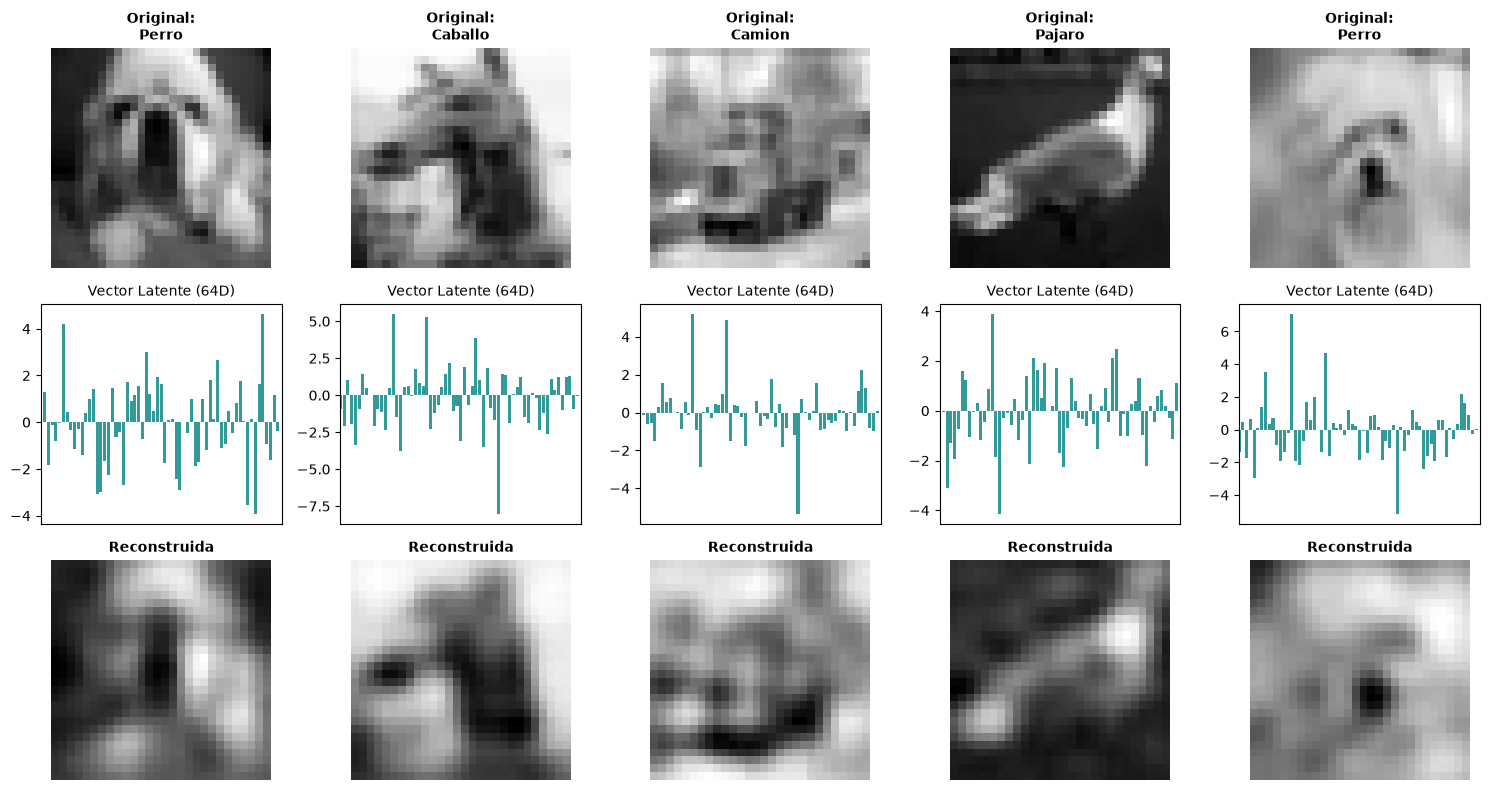

In [10]:
import matplotlib.pyplot as plt

# 1. Cargar datos de prueba
test_dataset = datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform
)
test_loader = DataLoader(dataset=test_dataset, batch_size=5, shuffle=True)

# 2. Obtener un lote de 5 imágenes para la visualización detallada
model.eval()
with torch.no_grad():
  images, labels = next(iter(test_loader))
  images = images.to(device)

  # Obtener el espacio latente y la reconstrucción
  latent_space = model.encoder(
      images
  )  # Forma: [Batch, 64, 1, 1]
  latent_vector = latent_space.view(
      latent_space.size(0), -1
  )  # Aplanar a [Batch, 64]
  reconstructed = model(images)

# Mover a CPU y convertir a numpy
images = images.cpu().numpy()
latent_vector = latent_vector.cpu().numpy()
reconstructed = reconstructed.cpu().numpy()

# Nombres de las clases de CIFAR-10 para contexto
class_names = [
    'Avion',
    'Automovil',
    'Pajaro',
    'Gato',
    'Ciervo',
    'Perro',
    'Rana',
    'Caballo',
    'Barco',
    'Camion',
]

# 3. Configurar la visualización en 3 filas: Original | Latente (Bar) | Reconstruida
fig, axes = plt.subplots(3, 5, figsize=(15, 8))

for i in range(5):
  # Fila 1: Imagen Original
  axes[0, i].imshow(images[i, 0], cmap='gray')
  axes[0, i].axis('off')
  axes[0, i].set_title(
      f'Original:\n{class_names[labels[i]]}', fontsize=10, fontweight='bold'
  )

  # Fila 2: Espacio Latente (Vector de 64 características como barras)
  axes[1, i].bar(range(64), latent_vector[i], color='teal', alpha=0.8)
  axes[1, i].set_xlim(0, 64)
  axes[1, i].set_title('Vector Latente (64D)', fontsize=10)
  axes[1, i].tick_params(
      axis='both', which='both', bottom=False, top=False, labelbottom=False
  )

  # Fila 3: Imagen Reconstruida
  axes[2, i].imshow(reconstructed[i, 0], cmap='gray')
  axes[2, i].axis('off')
  axes[2, i].set_title('Reconstruida', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()